# Predictor

In [1]:
import json, pickle, numpy as np, pandas as pd
from sentence_transformers import SentenceTransformer
from tqdm.notebook import tqdm
from pathlib import Path

/Users/paulschmitt/miniforge3/envs/de-wsd/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Load data

In [2]:
data_dir = Path("../data/processed")
germanet_dir = data_dir / "germanet_with_relations"
dwds_dir = data_dir / "dwds"

this is a big matrix where each row is a precomputed vector for one GermaNet synset’s

In [3]:
embeddings  = np.load(germanet_dir / "sense_embeddings.npz", mmap_mode="r")["X"]  # normalized vectors


Dict mapping synset ID → row index in emb-matrix.
Lets us slice just the candidate rows instantly

In [4]:
meta_data = pd.read_csv(germanet_dir / "sense_meta.csv", dtype=str)
sid_to_row = {sid:i for i, sid in enumerate(meta_data["synset_id"].tolist())}

Load candidate dicts

This constrains search to plausible senses (no global search needed)

In [5]:
with open(germanet_dir / "candidate_map.pkl","rb") as f:
    candidates = pickle.load(f)  # dict[(lemma,pos)] -> [synset_id]

Load model

In [6]:
model_name = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
model = SentenceTransformer(model_name)

In [7]:
def extract_context_window(sentence, lemma, window_size=3):
    """Extract context window around target word."""
    import re

    # Tokenize sentence (simple word split)
    words = sentence.lower().split()
    lemma_lower = lemma.lower()

    # Find lemma position (handle inflections by partial matching)
    target_pos = None
    for i, word in enumerate(words):
        # Remove punctuation for matching
        clean_word = re.sub(r'[^\w]', '', word)
        if lemma_lower in clean_word or clean_word in lemma_lower:
            target_pos = i
            break

    if target_pos is None:
        # Fallback to full sentence if lemma not found
        return sentence

    # Extract window
    start = max(0, target_pos - window_size)
    end = min(len(words), target_pos + window_size + 1)

    context_words = words[start:end]
    return " ".join(context_words)

**Comments:**

- Lookup & row mapping keep it O(k·d) (k≈2^15) instead of global search.

- Normalization lets us use a fast dot product for cosine.

- Threshold tau controls precision/coverage tradeoff:

    - higher tau ⇒ fewer but cleaner labels,

    - lower tau ⇒ more coverage with more noise.

In [8]:
def predict_one(lemma, pos, sentence, tau=0.33):
    # 1) Candidate lookup
    ids = candidates.get((lemma, pos), [])
    if not ids: return None, 0.0, "no-candidates"

    # 2) Map synset_ids -> row indices in X
    rows = [sid_to_row[i] for i in ids if i in sid_to_row]
    if not rows: return None, 0.0, "no-embeddings"

    # 3) Extract context window instead of full sentence
    context = extract_context_window(sentence, lemma, window_size=3)

    # 4) Embed the context (normalized)
    s = model.encode([context], convert_to_numpy=True, normalize_embeddings=True)[0]

    # 5) Compare to candidates (cosine via dot)
    #    X[rows] has shape [k, dim], s has [dim]
    scores = embeddings[rows] @ s

    # 6) Argmax + threshold
    j = int(scores.argmax())
    conf = float(scores[j])

    # 7) Confidence gating
    return (ids[j], conf, "context-window") if conf >= tau else (None, conf, "low-conf")

We don’t need a vector DB: we never search the whole space, only a tiny candidate set.

In [9]:
def extract_context_window(sentence, lemma, window_size=3):
    """Return a window of tokens around the first match (fallback: full sentence)."""
    import re
    words = re.findall(r"\w+", sentence)  # tokens, no punctuation
    lemma = lemma.lower()

    idx = next(
        (i for i, w in enumerate(words)
         if lemma in w.lower() or w.lower() in lemma),
        None
    )
    if idx is None:
        return sentence

    start = max(0, idx - window_size)
    end = min(len(words), idx + window_size + 1)
    return " ".join(words[start:end])

In [10]:
def run(in_path,
        out_path,
        tau=0.33):

    n, mapped = 0, 0
    with open(in_path,"r",encoding="utf-8") as fin, open(out_path,"w",encoding="utf-8") as fout:
        for line in fin:
            ex = json.loads(line)
            sid, conf, method = predict_one(ex["lemma"], ex["pos"], ex["sentence"], tau)
            ex.update({"synset_id": sid, "confidence": conf, "method": method})
            fout.write(json.dumps(ex, ensure_ascii=False) + "\n")
            n += 1; mapped += 1 if sid else 0

    print(f"✓ wrote {out_path} | mapped {mapped}/{n} ({mapped/n:.1%})")

In [11]:
dwds_input_path = dwds_dir / "dwds_target_words.jsonl"
dwds_output_path = dwds_dir / "wsd_atemporal_predictions.jsonl"

In [12]:
# Treshhold (can be adjusted)
tau = 0.3

In [13]:
# Run the WSD prediction pipeline
run(in_path=dwds_input_path,
    out_path=dwds_output_path,
    tau=tau)

✓ wrote ../data/processed/dwds/wsd_atemporal_predictions.jsonl | mapped 5177/6842 (75.7%)


# Analysis

In [14]:
# Load and analyze results
import matplotlib.pyplot as plt

results = []
with open(dwds_output_path, "r", encoding="utf-8") as f:
    for line in f:
        results.append(json.loads(line))

results_df = pd.DataFrame(results)
print(f"Total examples: {len(results_df)}")
print(f"Successfully mapped: {len(results_df[results_df['synset_id'].notna()])}")
print(f"Success rate: {len(results_df[results_df['synset_id'].notna()]) / len(results_df):.2%}")
print(f"\nMethod distribution:")
print(results_df['method'].value_counts())

Total examples: 6842
Successfully mapped: 5177
Success rate: 75.67%

Method distribution:
method
context-window    5177
low-conf          1665
Name: count, dtype: int64


In [15]:
results_df[["lemma", "sentence", "synset_id", "confidence"]]

,lemma,sentence,synset_id,confidence
0,Bank,Hawa setzte sich auf die um den tragenden Pfos...,s107676,0.602865
1,Bank,Sie saßen manchmal in der Küche beieinander od...,s6399,0.371544
2,Bank,Sie saßen nach dem Abendessen auf der Bank vor...,None,0.276398
3,Bank,Laut Gemeinschaftsvertrag kommt nur ein Teil d...,s107676,0.378830
4,Bank,Sie fuhr dafür nach Maria-Lach zu einem der Be...,s107676,0.593877
...,...,...,...,...
6837,hell,Am 25. März soll er in nur 39fachem Mondabstan...,None,0.276603
6838,hell,"Der Doktor, mit hellem Blick unter buschigen B...",s3147,0.308195
6839,hell,"Dann stützte ich mich an die Hauswand, sah auf...",s3018,0.392570
6840,hell,"Das neue Haus, in den siebziger oder achtziger...",s3018,0.473401


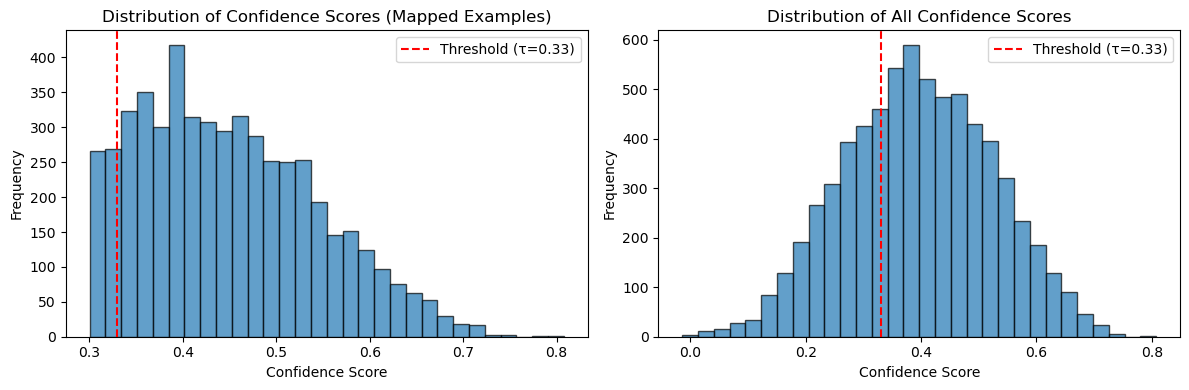

Mean confidence (mapped): 0.449
Median confidence (mapped): 0.437
Min confidence (mapped): 0.300
Max confidence (mapped): 0.808


In [16]:
# Confidence score distribution
mapped_results = results_df[results_df['synset_id'].notna()]

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.hist(mapped_results['confidence'], bins=30, alpha=0.7, edgecolor='black')
plt.xlabel('Confidence Score')
plt.ylabel('Frequency')
plt.title('Distribution of Confidence Scores (Mapped Examples)')
plt.axvline(x=0.33, color='red', linestyle='--', label='Threshold (τ=0.33)')
plt.legend()

plt.subplot(1, 2, 2)
plt.hist(results_df['confidence'], bins=30, alpha=0.7, edgecolor='black')
plt.xlabel('Confidence Score') 
plt.ylabel('Frequency')
plt.title('Distribution of All Confidence Scores')
plt.axvline(x=0.33, color='red', linestyle='--', label='Threshold (τ=0.33)')
plt.legend()

plt.tight_layout()
plt.show()

print(f"Mean confidence (mapped): {mapped_results['confidence'].mean():.3f}")
print(f"Median confidence (mapped): {mapped_results['confidence'].median():.3f}")
print(f"Min confidence (mapped): {mapped_results['confidence'].min():.3f}")
print(f"Max confidence (mapped): {mapped_results['confidence'].max():.3f}")

Threshold Analysis:
   threshold  mapped_count  success_rate  avg_confidence
0       0.10          6502         0.950           0.318
1       0.20          5449         0.796           0.350
2       0.30          3564         0.521           0.401
3       0.33          2867         0.419           0.422
4       0.40          1559         0.228           0.472
5       0.50           396         0.058           0.551
6       0.60            49         0.007           0.637
7       0.70             1         0.000           0.728


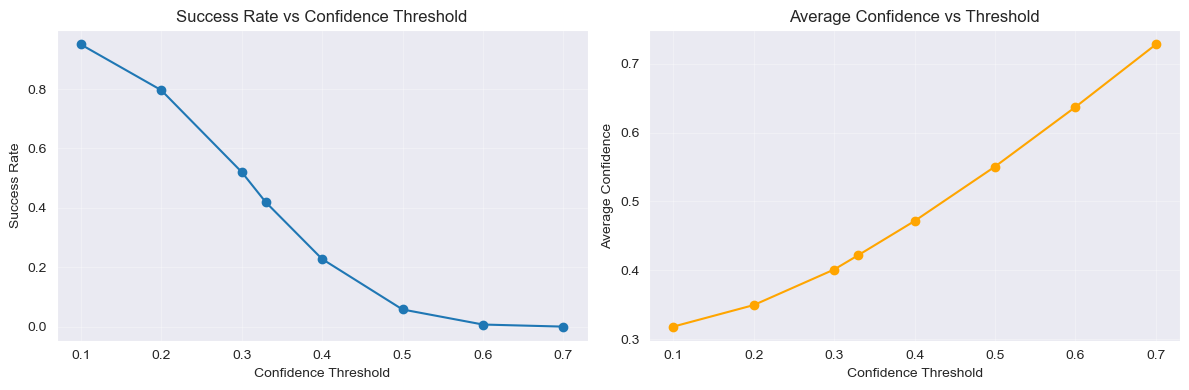

In [46]:
# Test different confidence thresholds
thresholds = [0.1, 0.2, 0.3, 0.33, 0.4, 0.5, 0.6, 0.7]
threshold_results = []

for tau in thresholds:
    mapped_count = len(results_df[results_df['confidence'] >= tau])
    success_rate = mapped_count / len(results_df)
    avg_conf = results_df[results_df['confidence'] >= tau]['confidence'].mean() if mapped_count > 0 else 0
    
    threshold_results.append({
        'threshold': tau,
        'mapped_count': mapped_count,
        'success_rate': success_rate,
        'avg_confidence': avg_conf
    })

threshold_df = pd.DataFrame(threshold_results)
print("Threshold Analysis:")
print(threshold_df.round(3))

# Plot threshold analysis
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(threshold_df['threshold'], threshold_df['success_rate'], 'o-')
plt.xlabel('Confidence Threshold')
plt.ylabel('Success Rate')
plt.title('Success Rate vs Confidence Threshold')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(threshold_df['threshold'], threshold_df['avg_confidence'], 'o-', color='orange')
plt.xlabel('Confidence Threshold')
plt.ylabel('Average Confidence')
plt.title('Average Confidence vs Threshold')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [47]:
# Quick sanity checks: Is this better than random?

# 1. Check some high-confidence examples manually
print("=== HIGH CONFIDENCE EXAMPLES ===")
high_conf = results_df[results_df['confidence'] > 0.7].head(10)
for _, row in high_conf.iterrows():
    print(f"Lemma: {row['lemma']} | Confidence: {row['confidence']:.3f}")
    print(f"Sentence: {row['sentence'][:100]}...")
    print(f"Synset: {row['synset_id']}")
    print()

print("\n=== RANDOM BASELINE ESTIMATE ===")
# Estimate random performance by looking at candidate set sizes
avg_candidates = []
unique_words = results_df[['lemma', 'pos']].drop_duplicates()
for _, row in unique_words.iterrows():
    lemma, pos = row['lemma'], row['pos']
    n_candidates = len(candidates.get((lemma, pos), []))
    avg_candidates.append(n_candidates)
    print(f"{lemma} ({pos}): {n_candidates} candidates")

mean_candidates = np.mean(avg_candidates)
random_baseline = 1 / mean_candidates if mean_candidates > 0 else 0
print(f"\nAverage candidates per word: {mean_candidates:.1f}")
print(f"Random baseline estimate: {random_baseline:.1%}")
print(f"Our performance: 52.2%")
print(f"Improvement over random: {52.2/100 / random_baseline:.1f}x" if random_baseline > 0 else "N/A")

=== HIGH CONFIDENCE EXAMPLES ===
Lemma: leicht | Confidence: 0.728
Sentence: Das ist auch leicht erklärlich....
Synset: s99381


=== RANDOM BASELINE ESTIMATE ===
Bank (NOUN): 5 candidates
Schloss (NOUN): 2 candidates
Leiter (NOUN): 3 candidates
Gericht (NOUN): 4 candidates
Steuer (NOUN): 4 candidates
Schimmel (NOUN): 2 candidates
Kiefer (NOUN): 3 candidates
Kreuz (NOUN): 6 candidates
Maus (NOUN): 2 candidates
Netz (NOUN): 3 candidates
Virus (NOUN): 2 candidates
Wolke (NOUN): 3 candidates
Monitor (NOUN): 3 candidates
Rechner (NOUN): 2 candidates
Speicher (NOUN): 3 candidates
Strom (NOUN): 4 candidates
Quelle (NOUN): 3 candidates
Zelle (NOUN): 5 candidates
Schalter (NOUN): 2 candidates
ziehen (VERB): 12 candidates
laden (VERB): 6 candidates
laufen (VERB): 9 candidates
schlagen (VERB): 15 candidates
tragen (VERB): 11 candidates
stellen (VERB): 6 candidates
setzen (VERB): 14 candidates
fahren (VERB): 8 candidates
teilen (VERB): 4 candidates
leicht (ADJ): 7 candidates
scharf (ADJ): 10 candi